# Multilingual Hate and Abusive-Language Detection for African Languages

**Course:** DSA 8401, Applied Machine Learning
**Author:** Gagandeep Singh Gahir, 114736

## About the project
This project builds a classifier that sorts social media posts in African languages into three classes: **Hate**, **Abusive** and **Normal**. It uses the AfriHate dataset, which has tweets in 15 African languages (for example Swahili, Amharic, Hausa, Yorùbá and isiZulu), annotated by native speakers.

Keyword filters miss context and often flag legitimate speech. The goal here is a moderation-assistance tool that supports human reviewers, not an automatic censor.

## Questions I want to answer
1. Can a multilingual model trained on some African languages work on a language it never saw during training?
2. Does performance differ a lot between languages, especially the low-resource ones?

## Approach
- **Data:** clean the raw tweets, check for duplicates and train/test leakage, and handle class imbalance.
- **Baseline:** TF-IDF with logistic regression (fast, CPU-only, robust to noisy spelling).
- **Main model:** AfroXLMR or AfriBERTa, fine-tuned on the data.
- **Evaluation:** macro-F1 per language (not accuracy), plus one language held out of training to test transfer.
- **Deployment:** a FastAPI service that returns the label and class probabilities, packaged with Docker.

In [7]:
import pandas as pd
from pathlib import Path

In [9]:
data_dir = Path("../data")
frames = []

for lang_folder in sorted(data_dir.iterdir()):
    if not (lang_folder / "train.tsv").exists():
        continue
    for split in ["train", "dev", "test"]:
        part = pd.read_csv(lang_folder / f"{split}.tsv", sep="\t")
        part["lang"] = lang_folder.name
        part["split"] = split
        frames.append(part)

all_data = pd.concat(frames, ignore_index=True)
print(all_data.shape)
all_data.head(10)

(90437, 6)


,id,tweet,label,lang,split,length
0,train_amharic_00001,@USER @USER @USER አላማህን አውቄብሃለው ማለት ነው ??? እኔ ...,Abuse,amh,train,NaN
1,train_amharic_00002,@USER ውጤታማ ከሆነ ዳግም ማፈናቀል ጭካኔአዊ ግድያ ከቆመ አንድ ሰው ...,Normal,amh,train,NaN
2,train_amharic_00003,@USER ሁለት ቀን ሆነኝ ከተኛዉ! እዉነት የሰራዊት ንጉስ ይፍረድ ???...,Hate,amh,train,NaN
3,train_amharic_00004,@USER ስለዚህ መንግስት ለአገራችን የሚበጀውን ነው የሚያደርገው እንጂ ...,Normal,amh,train,NaN
4,train_amharic_00005,የሰሞኑን የአዲስ አበባን ሁኔታ ሳስብ እቺ ቀልድ ትዝ አለችኝ,Normal,amh,train,NaN
5,train_amharic_00006,የ???? ብልፅግና ልክ እንደተጀመረዉ በህዝቦች አብሮነትና ሃገር ወዳድነት...,Normal,amh,train,NaN
6,train_amharic_00007,የኢትዮጵያ ከተሞች የትብብር መድረክ ከከተማና መሰረተ ልማት ሚኒስቴር ጋር...,Normal,amh,train,NaN
7,train_amharic_00008,@USER የምን ልምምጥ ነዉ ፋኖ በእጁ የ ያዘዉ ሙቅ ነዉ ግምባሩን በለው !,Hate,amh,train,NaN
8,train_amharic_00009,@USER እንደ ኤርሚያስ አጋሰስ አቁዋም የአለማችን የአየር ጸባይ እራሱ ...,Abuse,amh,train,NaN
9,train_amharic_00010,@USER ፈሪ አይደለሁም ለማለት ነው?,Abuse,amh,train,NaN


### Data Description and missing values

In [20]:
print(all_data.describe())

             length
count  30427.000000
mean     109.684655
std       79.015981
min        5.000000
25%       46.000000
50%       83.000000
75%      148.000000
max      764.000000


In [21]:
print(all_data.info())

<class 'pandas.DataFrame'>
RangeIndex: 90437 entries, 0 to 90436
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      90437 non-null  str    
 1   tweet   90437 non-null  str    
 2   label   90437 non-null  str    
 3   lang    90437 non-null  str    
 4   split   90437 non-null  str    
 5   length  30427 non-null  float64
dtypes: float64(1), str(5)
memory usage: 17.9 MB
None


In [22]:
print(all_data.columns.to_list())

['id', 'tweet', 'label', 'lang', 'split', 'length']


In [23]:
print(all_data.isnull().sum())

id            0
tweet         0
label         0
lang          0
split         0
length    60010
dtype: int64


### Tweets per lang

In [24]:
count_per_lang = all_data.groupby(["lang", "split"]).size().unstack(fill_value=0)

In [25]:
count_per_lang["total"] = count_per_lang.sum(axis=1)

In [26]:
count_per_lang.sort_values("total", ascending=False)

split,dev,test,train,total
lang,,,,
swa,3164,3168,14760,21092
pcm,1590,1593,7416,10599
hau,1029,1049,4566,6644
tir,760,765,3547,5072
orm,756,759,3517,5032
ibo,763,821,3419,5003
amh,744,747,3467,4958
yor,724,819,3336,4879
kin,706,714,3302,4722


### Label Balance

In [27]:
print(all_data["label"].value_counts())

label
Normal    36969
Abuse     36802
Hate      16666
Name: count, dtype: int64


In [28]:
all_data.groupby("lang")["label"].value_counts()

lang  label 
amh   Hate      2246
      Normal    1359
      Abuse     1353
arq   Abuse      778
      Normal     310
      Hate       162
ary   Abuse     2270
      Normal    1690
      Hate       674
hau   Normal    3965
      Abuse     2336
      Hate       343
ibo   Abuse     3510
      Normal    1242
      Hate       251
kin   Normal    2308
      Hate      1268
      Abuse     1146
orm   Hate      2293
      Normal    2072
      Abuse      667
pcm   Abuse     5238
      Normal    4184
      Hate      1177
som   Normal    2868
      Abuse     1404
      Hate       388
swa   Normal    9410
      Abuse     7708
      Hate      3974
tir   Hate      2940
      Abuse     1070
      Normal    1062
twi   Abuse     3278
      Hate       443
      Normal     180
xho   Normal    1923
      Abuse     1550
      Hate       210
yor   Abuse     2655
      Normal    2074
      Hate       150
zul   Normal    2322
      Abuse     1839
      Hate       147
Name: count, dtype: int64

In [29]:
train_rows = all_data[all_data["split"] == "train"].groupby("lang").size()
summary = train_rows.to_frame("train_rows")
summary["total_rows"] = all_data.groupby("lang").size()

label_share = pd.crosstab(all_data["lang"], all_data["label"], normalize="index").round(2)
summary = summary.join(label_share)

summary.sort_values("train_rows")

,train_rows,total_rows,Abuse,Hate,Normal
lang,,,,,
arq,716,1250,0.62,0.13,0.25
xho,2502,3683,0.42,0.06,0.52
twi,2564,3901,0.84,0.11,0.05
zul,2940,4308,0.43,0.03,0.54
som,3174,4660,0.30,0.08,0.62
ary,3240,4634,0.49,0.15,0.36
kin,3302,4722,0.24,0.27,0.49
yor,3336,4879,0.54,0.03,0.43
ibo,3419,5003,0.70,0.05,0.25


<Axes: xlabel='lang'>

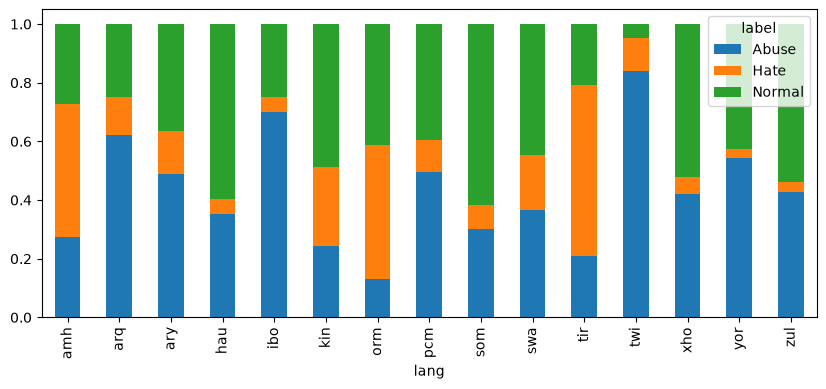

In [30]:
pd.crosstab(all_data["lang"], all_data["label"], normalize="index").plot(kind="bar", stacked=True, figsize=(10, 4))

### Held Out Language